# 01 · Data exploration

This notebook answers the open questions from the MS1 reviews before the feature pipeline is built.
It is documentation only and is **not exported** to a script. Raw snapshots are saved to `data/raw/exploration/`.

| # | Question | Label |
|---|----------|-------|
| 1 | How are SAKE releases published in CKAN (one replaced resource or a new one per quarter)? Which date fields exist? | A1 |
| 2 | Does BFS mark unreliable values (brackets, symbols, flag column)? | A2 / B1 |
| 3 | What does the SAKE table look like: segments, coverage, seasonality, noise in small segments? | A2 / B1 |
| 4 | How long after a quarter ends is SAKE published? | Leakage |
| 5 | WEA: one value per week, gaps, mapping of weeks to quarters | E1 / D2 |
| 6 | Which source offers the monthly LIK as machine-readable data with ongoing updates? | E1 |
| 7 | Do quarterly WEA and LIK move with unemployment at all? | E1 |

Decisions referred to as D1–D5 are in `docs/decisions.md`.

## Setup

In [47]:
import io
import re
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

CKAN = "https://ckan.opendata.swiss/api/3/action"
SAKE_DATASET = "erwerbslosenquote-gemass-ilo-nach-geschlecht-nationalitat-und-altersgruppen-durchschnittliche-m"
WEA_URL = "https://scheduler.swissdatas.ch/scheduled/wwa.csv"
START_QUARTER = pd.Period("2010Q1", freq="Q")

RAW_DIR = Path("../data/raw/exploration")
RAW_DIR.mkdir(parents=True, exist_ok=True)
TODAY = datetime.now(timezone.utc).strftime("%Y-%m-%d")

# Plot style: a colour-blind friendly palette, light grid, legends outside the data area
COLORS = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
plt.rcParams.update(
    {
        "axes.prop_cycle": plt.cycler(color=COLORS),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
        "legend.frameon": False,
    }
)

In [48]:
import time


def ckan(action: str, retries: int = 4, **params) -> dict:
    """Call the opendata.swiss CKAN API and return the result part.

    Retries on server errors (5xx) and timeouts, waiting 2, 4, 8 s between attempts.
    """
    for attempt in range(retries):
        try:
            r = requests.get(f"{CKAN}/{action}", params=params, timeout=30)
            if r.status_code < 500:
                r.raise_for_status()
                body = r.json()
                if not body.get("success"):
                    raise RuntimeError(body.get("error"))
                return body["result"]
            reason = f"HTTP {r.status_code}"
        except (requests.ConnectionError, requests.Timeout) as e:
            reason = type(e).__name__
        if attempt < retries - 1:
            wait = 2 ** (attempt + 1)
            print(f"{action}: {reason}, retrying in {wait} s")
            time.sleep(wait)
    raise RuntimeError(f"{action} failed after {retries} attempts ({reason})")


def pick_lang(value):
    """opendata.swiss stores titles as {'de': ..., 'fr': ..., 'en': ...}."""
    if isinstance(value, dict):
        for lang in ("en", "de", "fr", "it"):
            if value.get(lang):
                return value[lang]
        return next(iter(value.values()), None)
    return value


def resources_table(pkg: dict) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "id": r.get("id"),
            "name": pick_lang(r.get("title") or r.get("name")),
            "format": r.get("format"),
            "issued": r.get("issued"),
            "modified": r.get("modified") or r.get("last_modified"),
            "created": r.get("created"),
            "url": r.get("download_url") or r.get("url"),
        }
        for r in pkg.get("resources", [])
    )


def read_csv_any(content: bytes) -> pd.DataFrame:
    """Read a CSV with unknown encoding and separator, keeping every value as text."""
    for enc in ("utf-8-sig", "latin-1"):
        try:
            text = content.decode(enc)
            break
        except UnicodeDecodeError:
            continue
    header = text.splitlines()[0]
    sep = ";" if header.count(";") > header.count(",") else ","
    return pd.read_csv(io.StringIO(text), sep=sep, dtype=str)


def download(url: str, name: str, ext: str = ".csv") -> bytes:
    """Download a file and keep a dated snapshot in data/raw/exploration."""
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    path = RAW_DIR / f"{name}_{TODAY}{ext}"
    path.write_bytes(r.content)
    print(f"saved {path} ({len(r.content):,} bytes)")
    return r.content

## 1 · SAKE in CKAN: releases and dates (A1)

What to look for: does the dataset have one CSV resource that gets replaced each quarter, or one resource per release?
Which date fields change when BFS publishes (`modified` on the dataset, on the resource, or only a new resource)?
Run this notebook again after the next SAKE release and compare the two tables.

In [49]:
sake_pkg = ckan("package_show", id=SAKE_DATASET)

print("title:", pick_lang(sake_pkg.get("title")))
for field in ["issued", "modified", "metadata_created", "metadata_modified", "accrual_periodicity"]:
    print(f"{field:20} {sake_pkg.get(field)}")

sake_resources = resources_table(sake_pkg)
sake_resources

title: Erwerbslosenquote gemäss ILO nach Geschlecht, Nationalität und Altersgruppen. Durchschnittliche Monats-, Quartals- und Jahreswerte
issued               2026-08-18T06:30:00+00:00
modified             None
metadata_created     2026-08-18T12:02:11.317649
metadata_modified    2026-10-15T10:12:10.173748
accrual_periodicity  http://publications.europa.eu/resource/authority/frequency/QUARTERLY


,id,name,format,issued,modified,created,url
0,898760c6-f251-4e01-b5eb-b0f034c4b721,"Erwerbslosenquote gemäss ILO nach Geschlecht, Nationalität und Altersgruppen...",HTML,2026-08-18T06:30:00+00:00,NaN,2026-08-18T12:02:11.319811,https://www.bfs.admin.ch/asset/de/ts-x-03.03.01.03a
1,172be66d-fe33-4d96-9163-e757b74be14a,"Erwerbslosenquote gemäss ILO nach Geschlecht, Nationalität und Altersgruppen...",ODS,2026-08-18T06:30:00+00:00,2026-07-29T11:04:02.505000+00:00,2026-08-18T12:02:11.319812,https://dam-api.bfs.admin.ch/hub/api/dam/assets/36710313/appendix
2,c9b62cc9-84b2-4629-a1be-88b92a4ad00f,"Erwerbslosenquote gemäss ILO nach Geschlecht, Nationalität und Altersgruppen...",CSV,2026-08-18T06:30:00+00:00,2026-07-29T11:04:03.692000+00:00,2026-08-18T12:02:11.319807,https://dam-api.bfs.admin.ch/hub/api/dam/assets/36710313/master
3,def9c3d6-d31a-4763-a08d-41df56349e02,"Taux de chômage au sens du BIT selon le sexe, la nationalité et les groupes ...",HTML,2026-08-18T06:30:00+00:00,NaN,2026-08-18T12:02:11.319813,https://www.bfs.admin.ch/asset/fr/ts-x-03.03.01.03a


In [50]:
# Keep the metadata snapshot, so the next run can be compared with this one
(RAW_DIR / f"sake_ckan_{TODAY}.json").write_text(pd.Series(sake_pkg).to_json(force_ascii=False, indent=2))

21194

> **Findings (A1: resource structure and date fields)**
>
> - The dataset has 4 resources: HTML (de), HTML (fr), ODS and CSV. All carry `issued` = 2026-08-18, the publication date of the Q2 2026 release.
> - The CSV URL contains a BFS asset ID: `dam-api.bfs.admin.ch/hub/api/dam/assets/36710313/master`. The resource field `modified` (2026-07-29) is when BFS prepared the file, not the publication date.
> - The dataset's `metadata_created` is also 2026-08-18. BFS seems to re-create the CKAN entry with each release, so the asset ID, and possibly the dataset slug, may change.
> - `metadata_modified` shows the date of this run (2026-10-15). It changes whenever opendata.swiss re-harvests and is **not** a release signal.
>
> **Consequence:** detect a new release through the CSV resource's `issued` date and URL; find the dataset by search with the slug as a fallback. To be confirmed with the Q3 2026 release (two-release test, A1).

## 2 · SAKE table: raw values and reliability markers (A2 / B1)

Everything is read as text first, so no marker is lost in a number conversion.
The table is in long format: one row per segment, period and frequency (`FREQ` = M, Q or Y), with a `STATUS` code per value.

In [51]:
csv_resources = sake_resources[sake_resources["format"].fillna("").str.upper().str.contains("CSV")]
assert len(csv_resources), "No CSV resource found, check the resource table above"
if len(csv_resources) > 1:
    print("Several CSV resources, using the first one. Check which one is current:")
    display(csv_resources[["name", "modified", "url"]])

sake_url = csv_resources.iloc[0]["url"]
sake_raw = read_csv_any(download(sake_url, "sake", ".csv"))
print(sake_raw.shape)
sake_raw.head(10)

saved ../data/raw/exploration/sake_2026-10-15.csv (6,049,609 bytes)
(32562, 15)


,INDICATORS_HRCHY,INDICATORS_FR,INDICATORS_DE,GENDER_FR,GENDER_DE,NAT_FR,NAT_DE,DETAILS_FR,DETAILS_DE,PERIOD,FREQ,MEASURE_FR,MEASURE_DE,VALUE,STATUS
0,P,TOTAL,TOTAL,Total,Total,Total,Total,Total,Total,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,1.73445206762346,A
1,P_1,AGE,ALTER,Total,Total,Total,Total,15-24 ans,15-24 Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O
2,P_2,AGE,ALTER,Total,Total,Total,Total,25-39 ans,25-39 Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O
3,P_3,AGE,ALTER,Total,Total,Total,Total,40-54 ans,40-54 Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O
4,P_4,AGE,ALTER,Total,Total,Total,Total,55-64 ans,55-64 Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O
5,P_5,AGE,ALTER,Total,Total,Total,Total,65 ans+,65+ Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O
6,P,ORIGINE,HERKUNFT,Total,Total,Suisses et Suissesses,Schweizer und Schweizerinnen,Total,Total,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,1.55412990950499,A
7,P_1,AGE,ALTER,Total,Total,Suisses et Suissesses,Schweizer und Schweizerinnen,15-24 ans,15-24 Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O
8,P_2,AGE,ALTER,Total,Total,Suisses et Suissesses,Schweizer und Schweizerinnen,25-39 ans,25-39 Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O
9,P_3,AGE,ALTER,Total,Total,Suisses et Suissesses,Schweizer und Schweizerinnen,40-54 ans,40-54 Jahre,1991-M01,M,Moyennes mensuelles,Durchschnittliche Monatswerte,NaN,O


In [52]:
# One row per column: how many distinct values, and a few examples
pd.DataFrame(
    {
        "n_unique": sake_raw.nunique(),
        "n_missing": sake_raw.isna().sum(),
        "examples": [sake_raw[c].dropna().unique()[:6].tolist() for c in sake_raw.columns],
    }
)

,n_unique,n_missing,examples
INDICATORS_HRCHY,6,0,"[P, P_1, P_2, P_3, P_4, P_5]"
INDICATORS_FR,3,0,"[TOTAL, AGE, ORIGINE]"
INDICATORS_DE,3,0,"[TOTAL, ALTER, HERKUNFT]"
GENDER_FR,3,0,"[Total, Hommes, Femmes]"
GENDER_DE,3,0,"[Total, Männer, Frauen]"
NAT_FR,3,0,"[Total, Suisses et Suissesses, Etrangers et étrangères]"
NAT_DE,3,0,"[Total, Schweizer und Schweizerinnen, Ausländer and Ausländerinnen]"
DETAILS_FR,6,0,"[Total, 15-24 ans, 25-39 ans, 40-54 ans, 55-64 ans, 65 ans+]"
DETAILS_DE,6,0,"[Total, 15-24 Jahre, 25-39 Jahre, 40-54 Jahre, 55-64 Jahre, 65+ Jahre]"
PERIOD,603,0,"[1991-M01, 1991-M02, 1991-M03, 1991-M04, 1991-M05, 1991-M06]"


In [53]:
# Period formats per frequency
sake_raw.groupby("FREQ")["PERIOD"].agg(["min", "max", "nunique"])

,min,max,nunique
FREQ,,,
M,1991-M01,2026-M06,426
Q,1991-Q1,2026-Q2,142
Y,1991,2025,35


### STATUS codes

The codes look like the standard SDMX observation status: **A** normal value, **P** provisional, **U** low reliability, **O** missing.
Confirm this in the BFS metadata (HTML resource in section 1) before relying on it.

In [54]:
status = sake_raw.assign(has_value=sake_raw["VALUE"].notna())
pd.crosstab([status["FREQ"], status["STATUS"]], status["has_value"], margins=True)

has_value    False  True    All
FREQ STATUS                    
M    A           0  2868   2868
     O       20082     0  20082
     P           0    54     54
Q    A           0  2791   2791
     O        4138     0   4138
     U           0   739    739
Y    A           0   804    804
     O         951     0    951
     U           0   135    135
All          25171  7391  32562

> **Findings (A2 / B1: how BFS marks unreliable or suppressed values)**
>
> - Values carry no brackets or symbols. Reliability is a separate `STATUS` column with four codes, matching the SDMX observation status: **A** normal, **P** provisional, **U** low reliability, **O** missing (to confirm in the BFS metadata).
> - Every O row has no value, and every A, P and U row has one.
> - Quarterly values (all years): 2,791 A, 739 U, 4,138 O. P only appears in monthly values (54).
> - The table is in long format with three frequencies in `FREQ`: monthly (`1991-M01`), quarterly (`1991-Q1`) and yearly (`1991`).
>
> **Consequence:** store `STATUS` next to every value in the feature store and show U next to the forecast in the UI.

## 3 · Quarterly segments: coverage, seasonality, noise

A segment is one combination of gender, nationality and age group. The `INDICATORS_*` columns only describe where a row sits
in the BFS hierarchy and are not part of the segment. Only quarterly values (`FREQ == "Q"`) from 2010Q1 are used, without 65+.

In [55]:
GENDER, NAT, AGE = "GENDER_DE", "NAT_DE", "DETAILS_DE"

NAT_SHORT = {"Schweizer und Schweizerinnen": "Schweizer", "Ausländer and Ausländerinnen": "Ausländer", "Total": "Alle"}


def short_label(row) -> str:
    gender = "Alle" if row[GENDER] == "Total" else row[GENDER]
    nat = NAT_SHORT.get(row[NAT], row[NAT])
    age = "Alle Alter" if row[AGE] == "Total" else row[AGE].replace(" Jahre", "")
    if gender == nat == "Alle" and age == "Alle Alter":
        return "National total"
    return f"{gender} · {nat} · {age}"


def parse_quarter(value):
    """Turn '2024Q1', '2024-Q1', '2024-Q01' or '2024 T1' into a quarterly Period."""
    m = re.search(r"(\d{4})\s*[-/ ]?\s*[QqTtKk]\s*0?([1-4])\b", str(value))
    return pd.Period(year=int(m[1]), quarter=int(m[2]), freq="Q") if m else pd.NaT


q = sake_raw[sake_raw["FREQ"] == "Q"].copy()
q["quarter"] = q["PERIOD"].map(parse_quarter)
print("quarterly periods that could not be parsed:", q.loc[q["quarter"].isna(), "PERIOD"].unique()[:10])

q["value"] = pd.to_numeric(q["VALUE"], errors="coerce")
q["segment"] = q.apply(short_label, axis=1)

# Each segment should appear once per quarter. More than one row means the hierarchy repeats a combination.
dupes = q.groupby(["segment", "quarter"]).size()
print("max rows per segment and quarter:", dupes.max())
if dupes.max() > 1:
    display(q[q.set_index(["segment", "quarter"]).index.isin(dupes[dupes > 1].index)].head(10))

quarterly periods that could not be parsed: <ArrowStringArray>
[]
Length: 0, dtype: str
max rows per segment and quarter: 1


In [56]:
scoped = (
    q[(q["quarter"] >= START_QUARTER) & (q[AGE] != "65+ Jahre")]
    .drop_duplicates(["segment", "quarter"])
    .copy()
)
print("segments in scope:", scoped["segment"].nunique(), "(expected 45: national total + 44)")
print("quarters:", scoped["quarter"].min(), "to", scoped["quarter"].max())
print("status codes in scope:", scoped["STATUS"].value_counts().to_dict())

segments in scope: 45 (expected 45: national total + 44)
quarters: 2010Q1 to 2026Q2
status codes in scope: {'A': 2411, 'U': 559}


In [57]:
expected = len(pd.period_range(START_QUARTER, scoped["quarter"].max(), freq="Q"))


def segment_stats(g: pd.DataFrame) -> pd.Series:
    g = g.sort_values("quarter")
    return pd.Series(
        {
            "n_quarters": g["quarter"].nunique(),
            "n_with_value": int(g["value"].notna().sum()),
            "n_status_U": int((g["STATUS"] == "U").sum()),
            "n_status_P": int((g["STATUS"] == "P").sum()),
            "n_status_O": int((g["STATUS"] == "O").sum()),
            "mean_rate": g["value"].mean(),
            "std_qoq_change": g["value"].diff().std(),
        }
    )


seg_stats = scoped.groupby("segment").apply(segment_stats, include_groups=False)
seg_stats["noise_ratio"] = seg_stats["std_qoq_change"] / seg_stats["mean_rate"]
seg_meta = scoped.drop_duplicates("segment").set_index("segment")[[GENDER, NAT, AGE]]
seg_stats = seg_stats.join(seg_meta)

print("expected quarters per segment:", expected)
seg_stats.sort_values("noise_ratio", ascending=False).drop(columns=[GENDER, NAT, AGE]).round(3)

expected quarters per segment: 66


,n_quarters,n_with_value,n_status_U,n_status_P,n_status_O,mean_rate,std_qoq_change,noise_ratio
segment,,,,,,,,
Frauen · Schweizer · 15-24,66.0,66.0,31.0,0.0,0.0,6.780,2.766,0.408
Alle · Schweizer · 15-24,66.0,66.0,0.0,0.0,0.0,6.937,2.455,0.354
Männer · Schweizer · 15-24,66.0,66.0,24.0,0.0,0.0,7.090,2.485,0.351
Frauen · Alle · 15-24,66.0,66.0,1.0,0.0,0.0,8.072,2.765,0.343
Männer · Ausländer · 15-24,66.0,66.0,62.0,0.0,0.0,12.759,4.351,0.341
Frauen · Ausländer · 55-64,66.0,66.0,66.0,0.0,0.0,7.869,2.578,0.328
Frauen · Ausländer · 15-24,66.0,66.0,64.0,0.0,0.0,13.255,4.272,0.322
Alle · Alle · 15-24,66.0,66.0,0.0,0.0,0.0,8.205,2.388,0.291
Männer · Alle · 15-24,66.0,66.0,0.0,0.0,0.0,8.331,2.423,0.291


17 of 45 segments have missing or low-reliability quarters


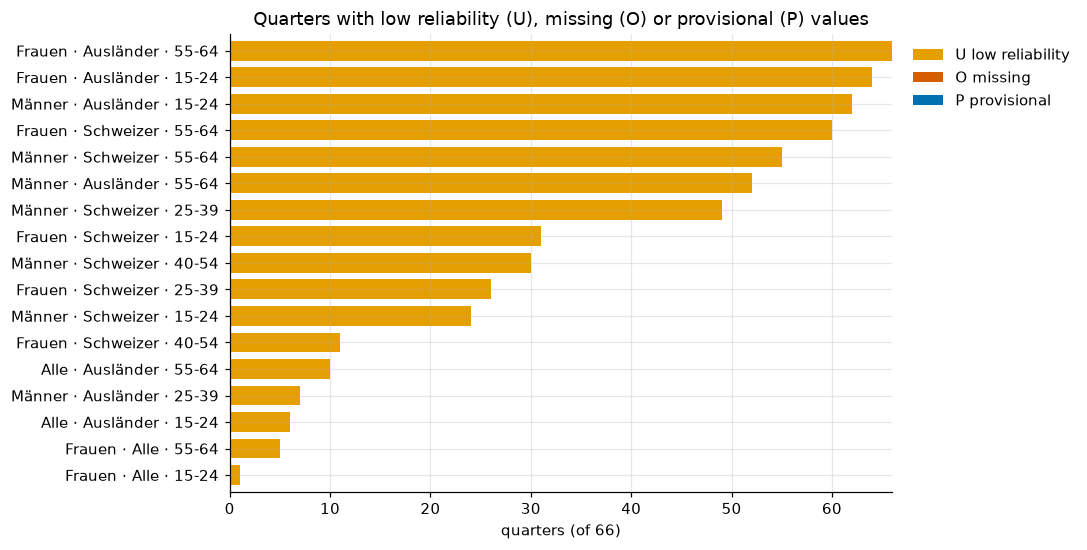

In [58]:
# Segments with missing or low-reliability quarters
problems = seg_stats[(seg_stats["n_with_value"] < expected) | (seg_stats["n_status_U"] > 0)]
print(f"{len(problems)} of {len(seg_stats)} segments have missing or low-reliability quarters")

if len(problems):
    counts = (
        problems[["n_status_U", "n_status_O", "n_status_P"]]
        .sort_values("n_status_U")
        .rename(columns={"n_status_U": "U low reliability", "n_status_O": "O missing", "n_status_P": "P provisional"})
    )
    fig, ax = plt.subplots(figsize=(10, max(3, 0.3 * len(counts))))
    counts.plot.barh(stacked=True, ax=ax, color=[COLORS[1], COLORS[3], COLORS[0]], width=0.75)
    ax.set_xlabel(f"quarters (of {expected})")
    ax.set_ylabel("")
    ax.set_title("Quarters with low reliability (U), missing (O) or provisional (P) values")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

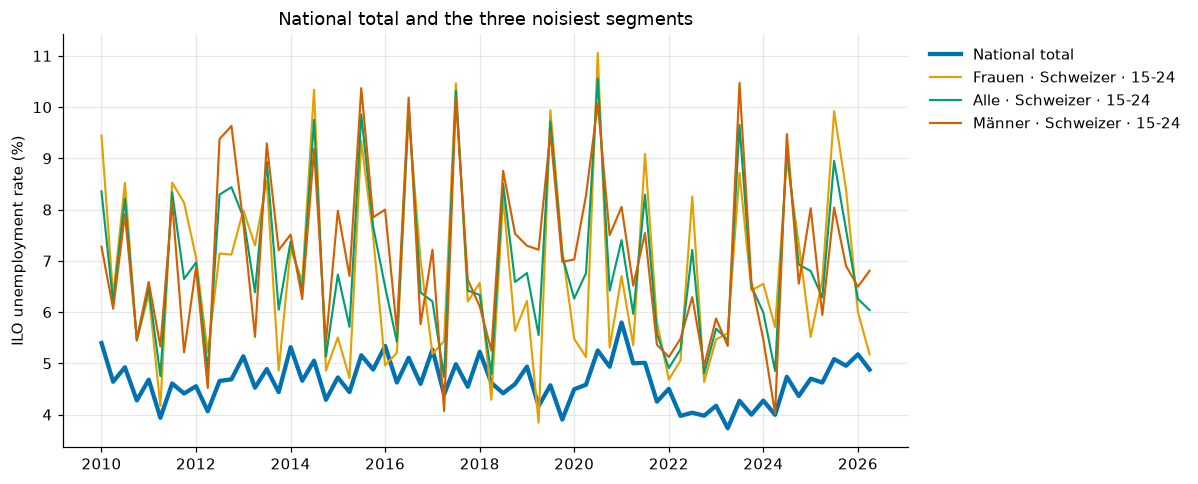

In [59]:
national = scoped[scoped["segment"] == "National total"].set_index("quarter")["value"].sort_index()
noisiest = seg_stats["noise_ratio"].nlargest(3).index.tolist()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(national.index.to_timestamp(), national.values, lw=2.8, color=COLORS[0], label="National total")
for color, seg in zip([COLORS[1], COLORS[2], COLORS[3]], noisiest):
    s = scoped[scoped["segment"] == seg].set_index("quarter")["value"].sort_index()
    ax.plot(s.index.to_timestamp(), s.values, lw=1.4, color=color, label=seg)
ax.set_ylabel("ILO unemployment rate (%)")
ax.set_title("National total and the three noisiest segments")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

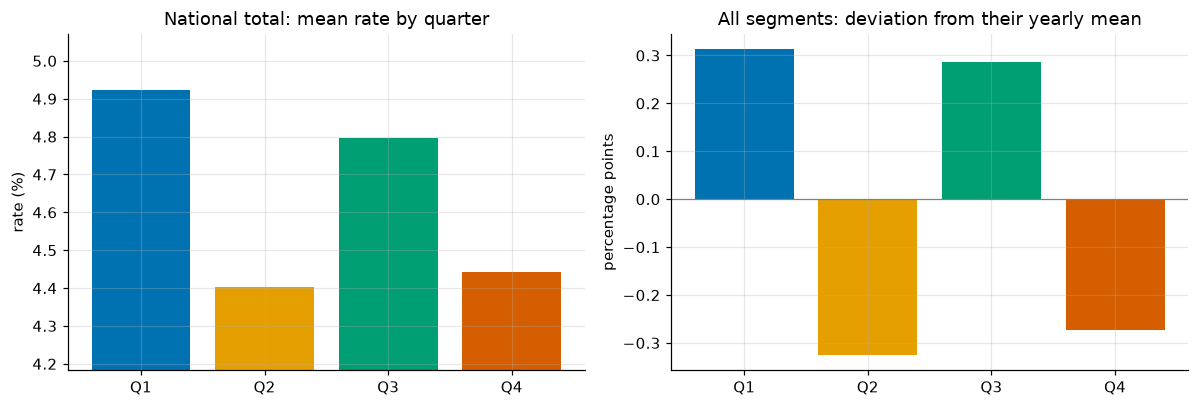

In [60]:
# Seasonality: average rate by quarter of the year (national), and the same pattern across all segments
season = scoped.assign(q=scoped["quarter"].dt.quarter, year=scoped["quarter"].dt.year)
season["deviation"] = season["value"] - season.groupby(["segment", "year"])["value"].transform("mean")
quarter_colors = COLORS[:4]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
national_by_q = national.groupby(national.index.quarter).mean()
axes[0].bar([f"Q{i}" for i in national_by_q.index], national_by_q.values, color=quarter_colors)
axes[0].set_ylim(national_by_q.min() * 0.95, national_by_q.max() * 1.03)
axes[0].set_title("National total: mean rate by quarter")
axes[0].set_ylabel("rate (%)")

dev_by_q = season.groupby("q")["deviation"].mean()
axes[1].bar([f"Q{i}" for i in dev_by_q.index], dev_by_q.values, color=quarter_colors)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_title("All segments: deviation from their yearly mean")
axes[1].set_ylabel("percentage points")
plt.tight_layout()
plt.show()

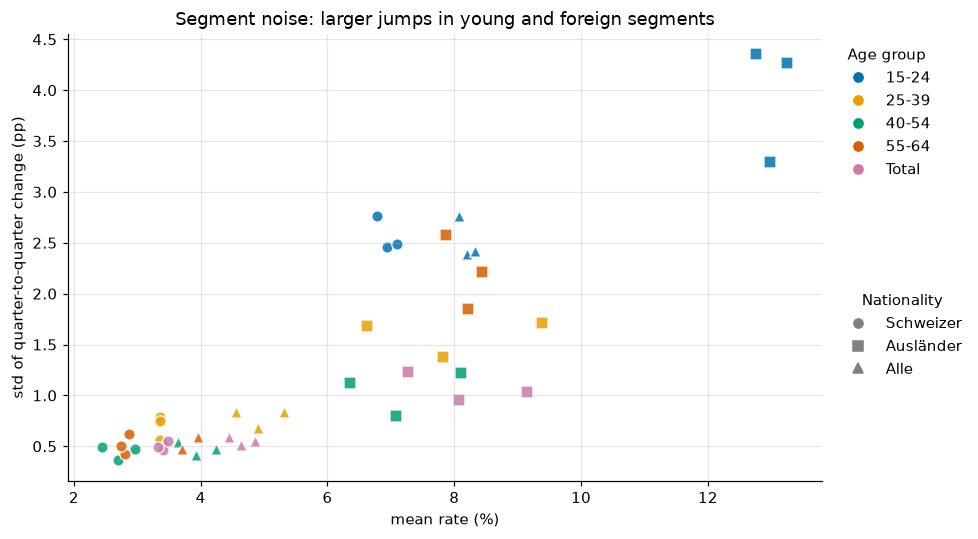

In [61]:
# Noise vs. level, coloured by age group and shaped by nationality
age_order = sorted(seg_stats[AGE].unique(), key=lambda a: (a == "Total", a))
nat_markers = {"Schweizer und Schweizerinnen": "o", "Ausländer and Ausländerinnen": "s", "Total": "^"}

fig, ax = plt.subplots(figsize=(9, 5))
for color, age in zip(COLORS, age_order):
    for nat, marker in nat_markers.items():
        sub = seg_stats[(seg_stats[AGE] == age) & (seg_stats[NAT] == nat)]
        if len(sub):
            ax.scatter(sub["mean_rate"], sub["std_qoq_change"], color=color, marker=marker, s=55, alpha=0.85, edgecolor="white")

age_handles = [plt.Line2D([], [], color=c, marker="o", ls="", label=a.replace(" Jahre", "")) for c, a in zip(COLORS, age_order)]
nat_handles = [plt.Line2D([], [], color="grey", marker=m, ls="", label=NAT_SHORT[n]) for n, m in nat_markers.items()]
first = ax.legend(handles=age_handles, title="Age group", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.add_artist(first)
ax.legend(handles=nat_handles, title="Nationality", loc="upper left", bbox_to_anchor=(1.01, 0.45))
ax.set_xlabel("mean rate (%)")
ax.set_ylabel("std of quarter-to-quarter change (pp)")
ax.set_title("Segment noise: larger jumps in young and foreign segments")
plt.tight_layout()
plt.show()

### Monthly values

The table also contains monthly averages (`FREQ == "M"`). Check whether they exist for the segments from 2010 and when they are published.
If they arrive only with the quarterly release, they do not make the pipeline more live.

In [62]:
m = sake_raw[(sake_raw["FREQ"] == "M")].copy()
m["month"] = pd.PeriodIndex(m["PERIOD"].str.replace("-M", "-", regex=False), freq="M")
m["segment"] = m.apply(short_label, axis=1)
m_scoped = m[(m["month"] >= pd.Period("2010-01", freq="M")) & (m[AGE] != "65+ Jahre")]
monthly_cov = m_scoped.groupby("segment")["VALUE"].apply(lambda s: s.notna().mean()).sort_values()
print("latest month with a national value:", m_scoped.loc[(m_scoped["segment"] == "National total") & m_scoped["VALUE"].notna(), "month"].max())
print("segments with monthly values for at least 90 % of months:", int((monthly_cov >= 0.9).sum()), "of", len(monthly_cov))
monthly_cov.describe()

latest month with a national value: 2026-06
segments with monthly values for at least 90 % of months: 9 of 45


count    45.00000
mean      0.20000
std       0.40452
min       0.00000
25%       0.00000
50%       0.00000
75%       0.00000
max       1.00000
Name: VALUE, dtype: float64

> **Findings (segments, coverage, seasonality, noisy segments, monthly values)**
>
> - 45 segments in scope (national total + 44), each with all 66 quarters from 2010Q1 to 2026Q2 and no missing values.
> - In scope, 2,411 quarterly values are A and 559 are U (19 %). 17 of 45 segments have U quarters. Some are U almost always:
>
> | Segment | U quarters (of 66) |
> |---|---|
> | Frauen · Ausländer · 55-64 | 66 |
> | Frauen · Ausländer · 15-24 | 64 |
> | Männer · Ausländer · 15-24 | 62 |
> | Frauen · Schweizer · 55-64 | 60 |
> | Männer · Schweizer · 55-64 | 55 |
> | Männer · Ausländer · 55-64 | 52 |
>
> - The 15-24 segments are the noisiest relative to their level (noise ratio 0.29–0.41). Young foreigners have the highest rates (about 13 %).
> - Monthly values exist for only 9 of 45 segments (age group "Total"). The latest month is 2026-06, so they arrive with the quarterly release and add no live data.
> - Strong seasonality: the values are not seasonally adjusted. Q1 and Q3 lie about 0.3 pp above the yearly mean, Q2 and Q4 about 0.3 pp below (national: 4.9 % in Q1 vs. 4.4 % in Q2). The 15-24 segments peak in Q3, when school leavers enter the labour market.
>
> **Consequence:** keep all 45 segments in model and UI, but measure the 15 % target only on segments that are mostly A, and report the mostly-U segments separately (A2 / B1, B2). Monthly SAKE values are not used. The quarter of the year is a required feature, and the seasonal-naive baseline is likely the harder one to beat.

## 4 · Publication lag (leakage, A1)

A forecast for quarter *t+1* is made when quarter *t* has been published. Features may only use WEA and LIK values that were
available at that moment. CKAN gives one data point (the latest release); confirm with the BFS release calendar.

`metadata_modified` changes whenever opendata.swiss re-harvests the dataset, so it is not a release signal.

In [63]:
latest_quarter = scoped["quarter"].max()
quarter_end = latest_quarter.end_time.normalize()
candidates = {
    "resource issued": csv_resources.iloc[0]["issued"],
    "resource modified": csv_resources.iloc[0]["modified"],
    "dataset issued": sake_pkg.get("issued"),
    "dataset metadata_modified": sake_pkg.get("metadata_modified"),
}
print("latest quarter in data:", latest_quarter, "ends", quarter_end.date())
for name, value in candidates.items():
    ts = pd.to_datetime(value, utc=True, errors="coerce") if value else pd.NaT
    if pd.notna(ts):
        print(f"{name:28} {ts.date()}  -> {(ts.tz_localize(None).normalize() - quarter_end).days} days after quarter end")
print("CSV url:", sake_url)

latest quarter in data: 2026Q2 ends 2026-06-30
resource issued              2026-08-18  -> 49 days after quarter end
resource modified            2026-07-29  -> 29 days after quarter end
dataset issued               2026-08-18  -> 49 days after quarter end
dataset metadata_modified    2026-10-15  -> 107 days after quarter end
CSV url: https://dam-api.bfs.admin.ch/hub/api/dam/assets/36710313/master


> **Findings (publication lag in days, which field marks a release, and the date of the next release)**
>
> - Q2 2026 was published on 2026-08-18, **49 days** after the quarter ended (resource and dataset `issued`).
> - With the same lag, Q3 2026 would be published around **2026-11-18**: after MS2 (5 Nov), before MS3 (3 Dec). Exact date to be checked in the BFS release calendar.
>
> **Consequence:** a forecast for quarter t+1 is made once quarter t is published, about 7 weeks into quarter t+1. Features may only use WEA and LIK values available at that date. The first release-triggered retraining can be shown at MS3.

## 5 · SECO Weekly Economic Activity (D2)

The file holds several series. Only `seco_wwa` is used (D2). A value of 1.0 means activity 1 % above the same week a year earlier.

In [64]:
wea_all = pd.read_csv(io.BytesIO(download(WEA_URL, "wea", ".csv")), parse_dates=["date"])
wea_all.groupby(["structure", "type", "seas_adj"]).agg(
    n=("value", "size"), first=("date", "min"), last=("date", "max")
)

saved ../data/raw/exploration/wea_2026-10-15.csv (62,344 bytes)


,,,n,first,last
structure,type,seas_adj,,,
seco_wwa,index,csa,1134,2005-01-03,2026-09-21
seco_wwa_pre_covid,index,csa,153,2019-12-30,2022-12-05


In [65]:
wea = wea_all[wea_all["structure"] == "seco_wwa"].sort_values("date").reset_index(drop=True)
if wea[["type", "seas_adj"]].drop_duplicates().shape[0] > 1:
    print("seco_wwa has several variants, filter on type and seas_adj too:")
    display(wea[["type", "seas_adj"]].drop_duplicates())

print("rows:", len(wea), "| from", wea["date"].min().date(), "to", wea["date"].max().date())
print("duplicate dates:", wea["date"].duplicated().sum())
print("days between rows:", wea["date"].diff().dt.days.value_counts().sort_index().to_dict())
print("weekdays of the dates:", wea["date"].dt.day_name().value_counts().to_dict())
print("missing values:", wea["value"].isna().sum())
wea[wea["value"].isna()]

rows: 1134 | from 2005-01-03 to 2026-09-21
duplicate dates: 0
days between rows: {7.0: 1133}
weekdays of the dates: {'Monday': 1134}
missing values: 3


,structure,type,seas_adj,date,value
260,seco_wwa,index,csa,2009-12-28,NaN
573,seco_wwa,index,csa,2015-12-28,NaN
834,seco_wwa,index,csa,2020-12-28,NaN


weeks per quarter: {12: 3, 13: 78, 14: 6}


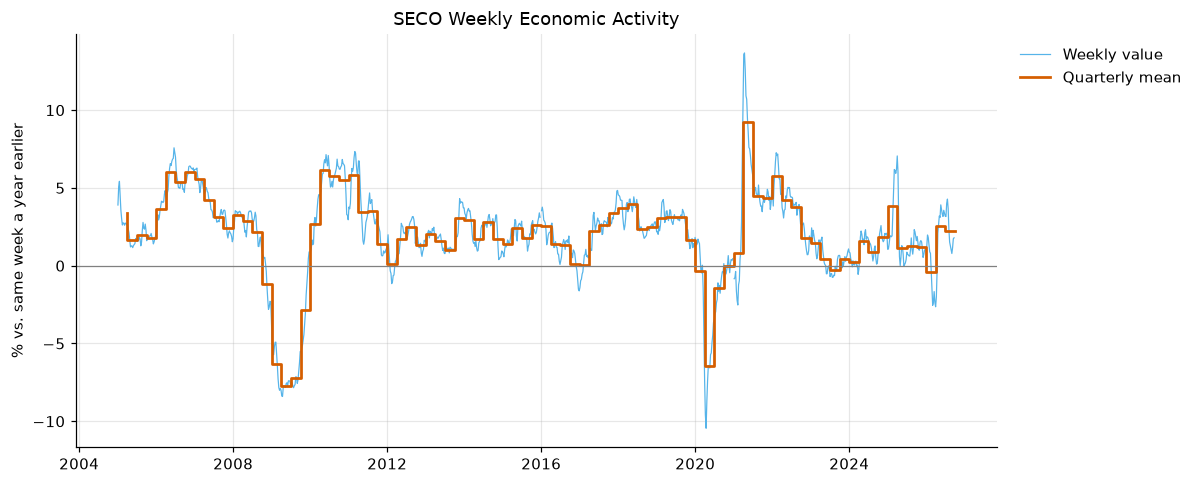

In [66]:
# Map weeks to quarters by the week's start date and count weeks per quarter
wea["quarter"] = wea["date"].dt.to_period("Q")
print("weeks per quarter:", wea.groupby("quarter").size().value_counts().sort_index().to_dict())

wea_q = wea.groupby("quarter")["value"].mean().rename("wea_mean")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(wea["date"], wea["value"], lw=0.8, color=COLORS[5], label="Weekly value")
ax.step(wea_q.index.to_timestamp(how="end"), wea_q.values, where="pre", color=COLORS[3], lw=1.8, label="Quarterly mean")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("% vs. same week a year earlier")
ax.set_title("SECO Weekly Economic Activity")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

> **Findings (WEA regularity, missing weeks, weeks per quarter)**
>
> - `seco_wwa`: 1,134 weekly values from 2005-01-03 to 2026-09-21, all dated on a Monday, exactly 7 days apart, no duplicates.
> - `seco_wwa_pre_covid` covers only 2019-12-30 to 2022-12-05 and is ignored (D2).
> - 3 missing values: 2009-12-28, 2015-12-28 and 2020-12-28. These are week 53 of years with 53 ISO weeks, which have no matching week a year earlier. The gaps are structural, not errors.
> - Quarters contain 12 to 14 weeks (mostly 13).
>
> **Consequence:** quarterly WEA features use the mean of available weeks, not the sum, and skip missing weeks.

## 6 · Monthly consumer prices (LIK) from the SNB data portal (D3)

The LIK is calculated by the BFS. opendata.swiss has no current machine-readable version of it, so the monthly series is
taken from the SNB data portal (cube `plkopr`), which republishes the BFS figures as CSV without an API key.
The file's second line holds the publication date, which is stored with every pull (D5).

saved ../data/raw/exploration/lik_snb_2026-10-15.csv (81,307 bytes)
published: 2026-09-21 09:00
{'LD2010100': 1268, 'VVP': 1268}
months: 1921-01 to 2026-08
missing since 2010: {'index': 0, 'inflation_yoy': 0}


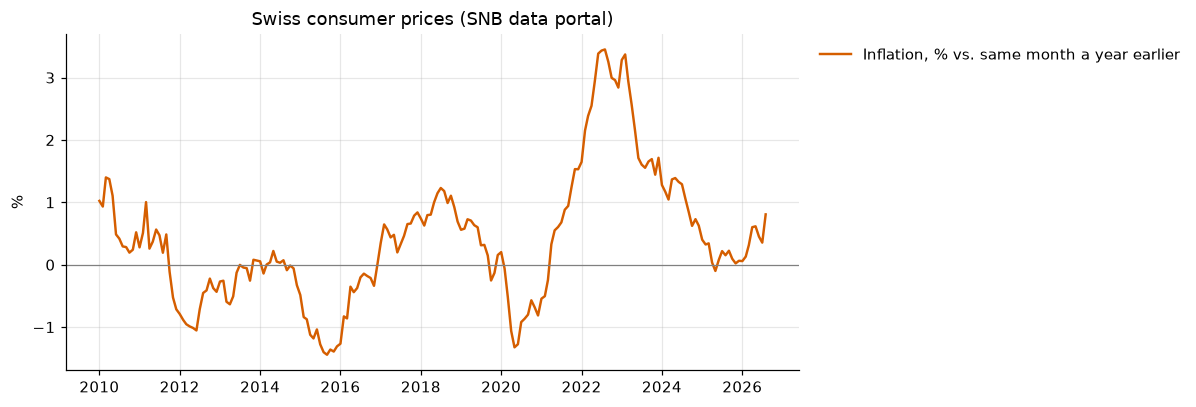

D0,index,inflation_yoy
Date,,
2025-09,100.4789,0.224430
2025-10,100.2230,0.095978
2025-11,100.0130,0.021202
2025-12,100.0000,0.063240
2026-01,99.9416,0.058068
2026-02,100.5738,0.130722
2026-03,100.8075,0.314654
2026-04,101.1045,0.601893
2026-05,101.2587,0.615865


In [67]:
LIK_URL = "https://data.snb.ch/api/cube/plkopr/data/csv/en"  # SNB data portal, CPI from the BFS

content = download(LIK_URL, "lik_snb", ".csv")
text = content.decode("utf-8-sig")
lik_published = text.splitlines()[1].split(";")[1].strip('"')  # 2nd line: "PublishingDate";"YYYY-MM-DD HH:MM"
print("published:", lik_published)

lik_raw = pd.read_csv(io.StringIO(text), sep=";", skiprows=2)
print(lik_raw["D0"].value_counts().to_dict())

lik_m = lik_raw.pivot(index="Date", columns="D0", values="Value")
lik_m.index = pd.PeriodIndex(lik_m.index, freq="M")
lik_m = lik_m.rename(columns={"LD2010100": "index", "VVP": "inflation_yoy"})
print("months:", lik_m.index.min(), "to", lik_m.index.max())
print("missing since 2010:", lik_m.loc["2010-01":].isna().sum().to_dict())

fig, ax = plt.subplots(figsize=(11, 3.8))
recent = lik_m.loc["2010-01":, "inflation_yoy"]
ax.plot(recent.index.to_timestamp(), recent.values, color=COLORS[3], lw=1.6, label="Inflation, % vs. same month a year earlier")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Swiss consumer prices (SNB data portal)")
ax.set_ylabel("%")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()
lik_m.loc["2010-01":].tail(12)

> **Findings (LIK source, format, monthly history from 2010?)**
>
> - opendata.swiss has no usable source: `landesindex-der-konsumentenpreise` is published by Kanton Zug, the BFS datasets per year only offer HTML and PDF, and the BFS table "CPI (december 2015=100), detailed results since 1982" was last updated in February 2021 (old basket, `.xls`).
> - Used instead: SNB data portal, cube `plkopr`, CSV without API key: `https://data.snb.ch/api/cube/plkopr/data/csv/en`.
> - Two series: `LD2010100` index and `VVP` change vs. the same month a year earlier in %. Despite the code name, the index equals exactly 100.0 in December 2025, so it is currently based on December 2025 = 100. Only `VVP` is used, which does not depend on the base.
> - Monthly values from 1921-01 to 2026-08, no missing values since 2010. Publication date of this pull: 2026-09-21, about 3 weeks after the end of August.
>
> **Consequence:** the pipeline reads `VVP` (year-on-year inflation) directly and stores the `PublishingDate` with every pull. D3 in `docs/decisions.md` is updated with this source.

## 7 · Do WEA and LIK move with unemployment? (E1)

A rough check, not a model: correlation between the national rate (its level and its quarter-to-quarter change) and the
indicator *k* quarters earlier. A negative correlation for WEA (more activity, falling unemployment) supports using it as a feature.

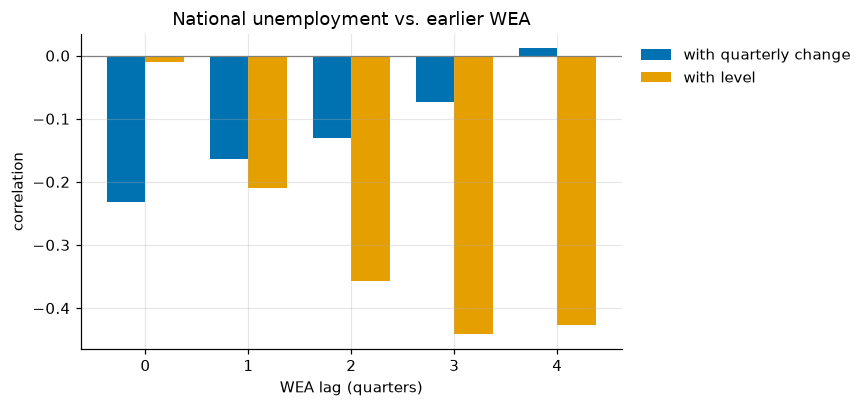

,corr_with_change,corr_with_level
lag_quarters,,
0,-0.232,-0.010
1,-0.163,-0.210
2,-0.131,-0.357
3,-0.073,-0.442
4,0.011,-0.427


In [68]:
nat = national.to_frame("rate")
nat["rate_change"] = nat["rate"].diff()
joined = nat.join(wea_q, how="inner")

lag_corr = pd.DataFrame(
    {
        "lag_quarters": k,
        "corr_with_change": joined["rate_change"].corr(joined["wea_mean"].shift(k)),
        "corr_with_level": joined["rate"].corr(joined["wea_mean"].shift(k)),
    }
    for k in range(0, 5)
).set_index("lag_quarters")

fig, ax = plt.subplots(figsize=(8, 3.8))
lag_corr.rename(columns={"corr_with_change": "with quarterly change", "corr_with_level": "with level"}).plot.bar(
    ax=ax, color=[COLORS[0], COLORS[1]], width=0.75, rot=0
)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("WEA lag (quarters)")
ax.set_ylabel("correlation")
ax.set_title("National unemployment vs. earlier WEA")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()
lag_corr.round(3)

In [69]:
# Inflation: quarterly mean of the monthly year-on-year change
lik_q = lik_m["inflation_yoy"].groupby(lik_m.index.asfreq("Q")).mean()

joined_lik = nat.join(lik_q.rename("inflation"), how="inner")
pd.DataFrame(
    {
        "lag_quarters": k,
        "corr_with_change": joined_lik["rate_change"].corr(joined_lik["inflation"].shift(k)),
        "corr_with_level": joined_lik["rate"].corr(joined_lik["inflation"].shift(k)),
    }
    for k in range(0, 5)
).set_index("lag_quarters").round(3)

,corr_with_change,corr_with_level
lag_quarters,,
0,-0.116,-0.464
1,-0.095,-0.592
2,-0.013,-0.606
3,-0.019,-0.629
4,0.086,-0.529


In [70]:
# Year-on-year change removes the seasonal pattern
nat["rate_yoy"] = nat["rate"] - nat["rate"].shift(4)
both = nat.join(wea_q).join(lik_q.rename("inflation"))

pd.DataFrame(
    {
        "lag_quarters": k,
        "WEA, with yoy change": both["rate_yoy"].corr(both["wea_mean"].shift(k)),
        "Inflation, with yoy change": both["rate_yoy"].corr(both["inflation"].shift(k)),
    }
    for k in range(0, 5)
).set_index("lag_quarters").round(3)

,"WEA, with yoy change","Inflation, with yoy change"
lag_quarters,,
0,-0.364,-0.503
1,-0.549,-0.462
2,-0.655,-0.361
3,-0.645,-0.239
4,-0.400,-0.051


> **Findings (signal of WEA and LIK, best lag)**
>
> Correlation of national unemployment with each indicator k quarters earlier (66 quarters):
>
> | Lag | WEA, q/q change | WEA, yoy change | WEA, level | Inflation, q/q change | Inflation, yoy change | Inflation, level |
> |---|---|---|---|---|---|---|
> | 0 | −0.23 | −0.36 | −0.01 | −0.12 | −0.50 | −0.46 |
> | 1 | −0.16 | −0.55 | −0.21 | −0.10 | −0.46 | −0.59 |
> | 2 | −0.13 | −0.66 | −0.36 | −0.01 | −0.36 | −0.61 |
> | 3 | −0.07 | −0.65 | −0.44 | −0.02 | −0.24 | −0.63 |
> | 4 | 0.01 | −0.40 | −0.43 | 0.09 | −0.05 | −0.53 |
>
> - The quarter-to-quarter change is dominated by seasonality (section 3). The year-on-year change (vs. the same quarter a year earlier) removes it and shows the economic signal.
> - WEA: higher activity goes with falling unemployment, strongest 2–3 quarters back (−0.66). Economic activity leads unemployment by about half a year to a year.
> - Inflation: strongest in the same quarter (−0.50), fading with distance.
> - Correlations over 66 quarters, so an indication, not proof.
>
> **Consequence:** the model predicts the year-on-year change; the forecast is the same quarter last year plus that change (D6). Features: WEA and inflation, current and lagged 1–4 quarters. MAE is still measured on the rate.

## Summary for `docs/ms2_summary.pdf` and `docs/decisions.md`

| # | Question | Answer | Consequence for the pipeline |
|---|----------|--------|------------------------------|
| 1 | SAKE release structure in CKAN | 4 resources, all `issued` on the release date. CSV URL contains a BFS asset ID; the CKAN entry seems to be re-created per release | Detect releases by `issued` and URL, find the dataset by search. Confirm with Q3 2026 (A1) |
| 2 | Reliability markers | Separate `STATUS` column: A, P, U, O. 19 % of in-scope quarterly values are U | Store `STATUS` per value, show U in the UI (A2 / B1) |
| 3 | Segments in scope, gaps, noisiest segments | 45 segments, 66 quarters each, no gaps. 6 segments are U almost always. 15-24 segments are the noisiest | 15 % target only on mostly-A segments, mostly-U segments reported separately (A2 / B1, B2) |
| 4 | Publication lag, next release date | 49 days. Q3 2026 expected around 18 Nov (to confirm) | Features only use data available at release. First retraining at MS3 |
| 5 | WEA regularity and quarter mapping | Weekly on Mondays since 2005, 3 structural gaps (week 53), 12–14 weeks per quarter | Quarterly mean of available weeks |
| 6 | LIK dataset and format | No current machine-readable LIK on opendata.swiss. SNB data portal, cube `plkopr`, monthly CSV with publication date | Ingest `VVP` (year-on-year inflation) from the SNB, store `PublishingDate` |
| 7 | WEA / LIK signal | Both explain the year-on-year change: WEA strongest 2–3 quarters back (−0.66), inflation in the same quarter (−0.50). The q/q change is dominated by seasonality | Target: year-on-year change (D6). WEA and inflation features, current and 1–4 quarters back |